In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
df = pd.read_csv("Telco_Customer_Churn_Dataset .csv")
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'],
    errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(0)
print(df.shape)

(7043, 21)


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")

In [3]:
contract_churn = (
    df.groupby('Contract')['Churn']
    .apply(lambda x: (x == 'Yes').mean() * 100)
    .sort_values(ascending=False))
print("Churn Rate by Contract:")
print(contract_churn)

payment_churn = (
    df.groupby('PaymentMethod')['Churn']
    .apply(lambda x: (x == 'Yes').mean() * 100)
    .sort_values(ascending=False))
print("\nChurn Rate by Payment Method:")
print(payment_churn)

internet_churn = (
    df.groupby('InternetService')['Churn']
    .apply(lambda x: (x == 'Yes').mean() * 100)
    .sort_values(ascending=False))
print("\nChurn Rate by Internet Service:")
print(internet_churn)

Churn Rate by Contract:
Contract
Month-to-month    42.709677
One year          11.269518
Two year           2.831858
Name: Churn, dtype: float64

Churn Rate by Payment Method:
PaymentMethod
Electronic check             45.285412
Mailed check                 19.106700
Bank transfer (automatic)    16.709845
Credit card (automatic)      15.243101
Name: Churn, dtype: float64

Churn Rate by Internet Service:
InternetService
Fiber optic    41.892765
DSL            18.959108
No              7.404980
Name: Churn, dtype: float64


In [4]:
df['EstimatedLTV'] = (
    df['MonthlyCharges'] * df['tenure'])
df[ [ 'customerID',
      'tenure',
      'MonthlyCharges',
      'EstimatedLTV',
      'Churn' ]].head()

,customerID,tenure,MonthlyCharges,EstimatedLTV,Churn
0,7590-VHVEG,1,29.85,29.85,No
1,5575-GNVDE,34,56.95,1936.30,No
2,3668-QPYBK,2,53.85,107.70,Yes
3,7795-CFOCW,45,42.30,1903.50,No
4,9237-HQITU,2,70.70,141.40,Yes


In [5]:
print("Average Estimated LTV:",
      round(df['EstimatedLTV'].mean(), 2))
print("Median Estimated LTV:",
      round(df['EstimatedLTV'].median(), 2))
print("Maximum Estimated LTV:",
      round(df['EstimatedLTV'].max(), 2))

Average Estimated LTV: 2279.58
Median Estimated LTV: 1393.6
Maximum Estimated LTV: 8550.0


In [6]:
df['ValueSegment'] = pd.qcut(
    df['EstimatedLTV'],
    q=3,
    labels=[
        'Low Value',
        'Medium Value',
        'High Value'],
    duplicates='drop')

In [7]:
print(df['ValueSegment']
    .value_counts()
    .sort_index())

ValueSegment
Low Value       2349
Medium Value    2346
High Value      2348
Name: count, dtype: int64


ValueSegment
Low Value       39.250745
Medium Value    23.785166
High Value      16.567291
Name: Churn, dtype: float64


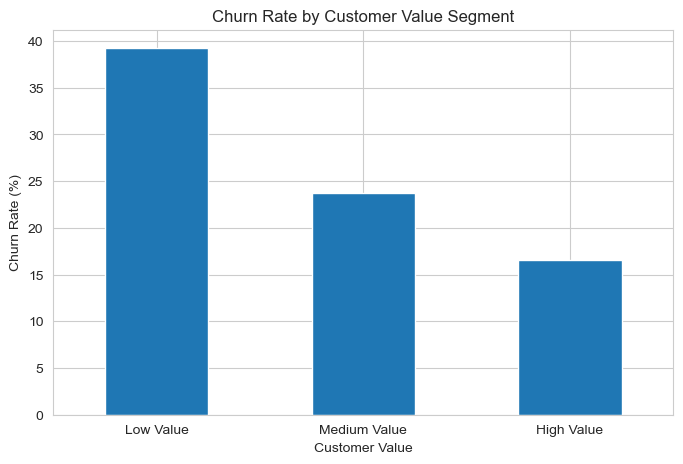

In [8]:
value_churn = (
    df.groupby(
        'ValueSegment',
        observed=False
    )['Churn'].apply(lambda x: (x == 'Yes').mean() * 100))
print(value_churn)

plt.figure(figsize=(8, 5))
value_churn.plot(kind='bar')
plt.title('Churn Rate by Customer Value Segment')
plt.xlabel('Customer Value')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)
plt.show()

In [9]:
# Prepare the complete dataset in the same format used by Task 4
risk_data = df.copy()
columns_to_drop = [
    'customerID',
    'Churn',
    'ChurnFlag',
    'TenureGroup',
    'TenureSegment',
    'ChargeSegment',
    'EstimatedLTV',
    'ValueSegment']
risk_data = risk_data.drop(
    columns=[
        col for col in columns_to_drop
        if col in risk_data.columns ])
print("Risk data shape:", risk_data.shape)

Risk data shape: (7043, 19)


In [10]:
print(df.columns.tolist())

['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn', 'EstimatedLTV', 'ValueSegment']


In [11]:
# Create a copy for prediction
risk_data = df.copy()
# Remove columns that were not used when training the model
columns_to_drop = [
    'customerID',
    'Churn',
    'ChurnFlag',
    'TenureGroup',
    'TenureSegment',
    'ChargeSegment',
    'EstimatedLTV',
    'ValueSegment',
    'ChurnProbability',
    'RiskCategory']
risk_data = risk_data.drop(
    columns=[
        col for col in columns_to_drop
        if col in risk_data.columns ])
print("Prediction data shape:", risk_data.shape)

Prediction data shape: (7043, 19)


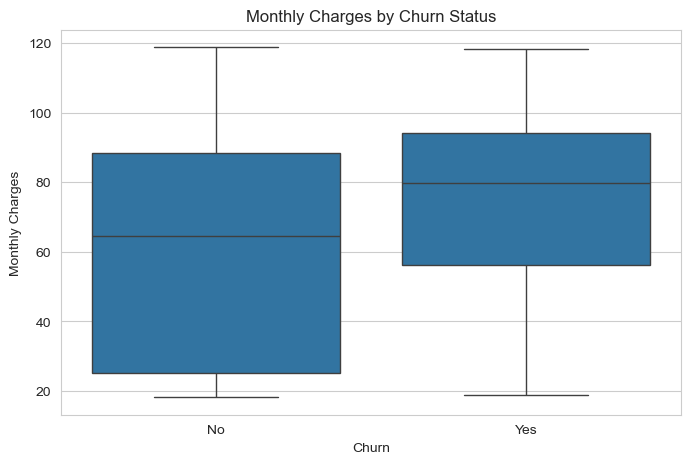

In [18]:
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df,
    x='Churn',
    y='MonthlyCharges')
plt.title('Monthly Charges by Churn Status')
plt.xlabel('Churn')
plt.ylabel('Monthly Charges')
plt.show()

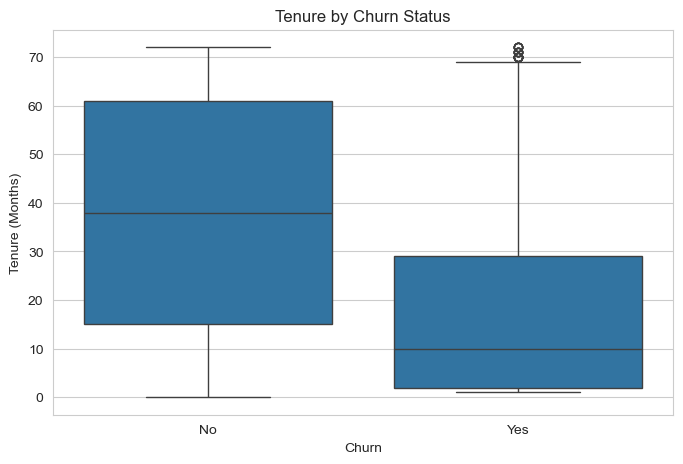

In [19]:
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df,
    x='Churn',
    y='tenure')
plt.title('Tenure by Churn Status')
plt.xlabel('Churn')
plt.ylabel('Tenure (Months)')
plt.show()

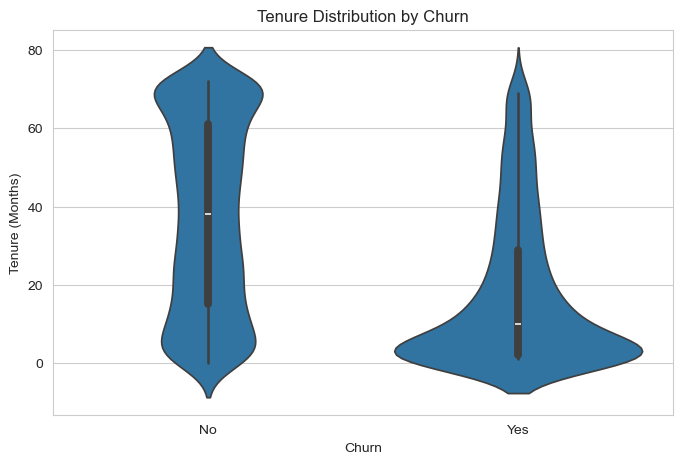

In [20]:
plt.figure(figsize=(8, 5))
sns.violinplot(
    data=df,
    x='Churn',
    y='tenure')
plt.title('Tenure Distribution by Churn')
plt.xlabel('Churn')
plt.ylabel('Tenure (Months)')
plt.show()

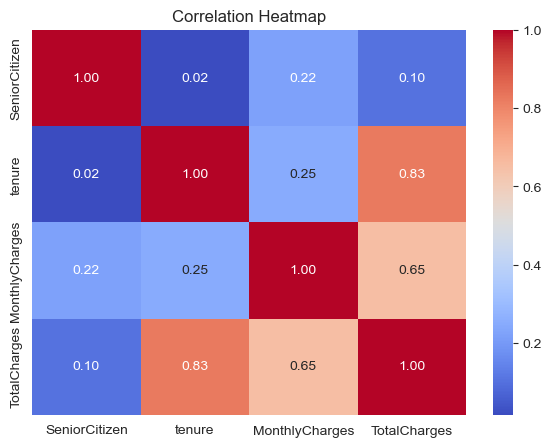

In [21]:
correlation_data = df[[
        'SeniorCitizen',
        'tenure',
        'MonthlyCharges',
        'TotalCharges' ]].corr()
plt.figure(figsize=(7, 5))
sns.heatmap(
    correlation_data,
    annot=True,
    fmt='.2f',
    cmap='coolwarm'
)
plt.title('Correlation Heatmap')
plt.show()

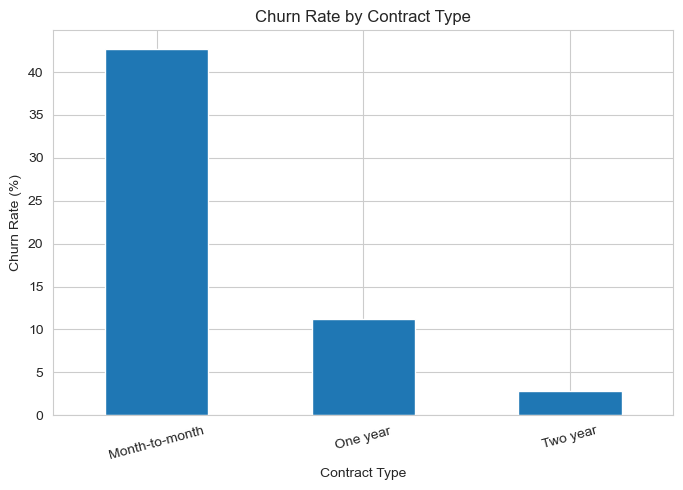

In [23]:
contract_churn = (
    df.groupby('Contract')['Churn']
    .apply(lambda x: (x == 'Yes').mean() * 100))
plt.figure(figsize=(8, 5))
contract_churn.plot(kind='bar')
plt.title('Churn Rate by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=15)
plt.show()